In [12]:
pip install scikit-learn

   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ------- -------------------------------- 1.6/8.2 MB 12.9 MB/s eta 0:00:01
   ----------------- ---------------------- 3.7/8.2 MB 12.8 MB/s eta 0:00:01
   -------------------------- ------------- 5.5/8.2 MB 9.5 MB/s eta 0:00:01
   ---------------------------------------  8.1/8.2 MB 10.8 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 9.9 MB/s  0:00:00
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   --- ------------------------------------ 3.1/36.6 MB 14.8 MB/s eta 0:00:03
   ------ --------------------------------- 5.8/36.6 MB 13.5 MB/s eta 0:00:03
   --------- ------------------------------ 8.4/36.6 MB 13.0 MB/s eta 0:00:03
   ----------- ---------------------------- 10.5/36.6 MB 12.4 MB/s eta 0:00:03
   -------------- ------------------------- 13.6/36.6 MB 12.9 MB/s eta 0:00:02
   ----------------- ---------------------- 16.0/36.6 MB 12.6 MB/s eta 0:00:02
   -------


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score


In [5]:
df = pd.read_csv("cleaned_HR_job_placement_dataset.csv")

In [6]:
df.shape

(50124, 32)

In [7]:
df['status'] = df['status'].map({'Placed': 1, 'Not Placed': 0})


In [8]:
df['status'].value_counts

<bound method IndexOpsMixin.value_counts of 0        0
1        0
2        1
3        0
4        0
        ..
50119    0
50120    0
50121    0
50122    1
50123    1
Name: status, Length: 50124, dtype: int64>

In [19]:
y = df['status']

X = df.drop(columns=['status','placement_probability_score'])

In [20]:
X_encoded = pd.get_dummies(X, drop_first=True)

print("Features shape after encoding:", X_encoded.shape)

Features shape after encoding: (50124, 39)


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 40099
Testing records: 10025


In [22]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf_model.fit(X_train, y_train)

print("Model training complete!")

Model training complete!


In [23]:
y_pred = rf_model.predict(X_test)

print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%\n")
print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

Model Accuracy: 86.73 %

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.87      0.95      0.91      6990
           1       0.86      0.68      0.75      3035

    accuracy                           0.87     10025
   macro avg       0.86      0.81      0.83     10025
weighted avg       0.87      0.87      0.86     10025



C:\Users\DELL\AppData\Local\Temp\ipykernel_17984\2498339413.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_features.values, y=top_10_features.index, palette='Blues_r')


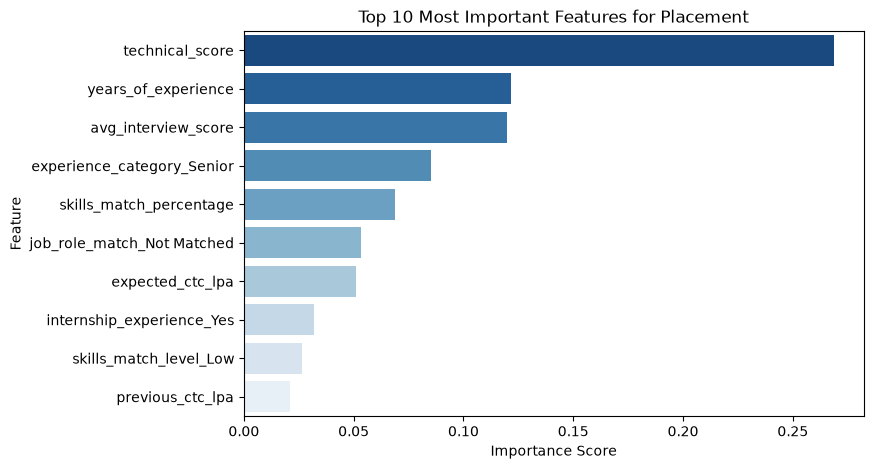

In [25]:
feature_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
top_10_features = feature_importances.nlargest(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_10_features.values, y=top_10_features.index, palette='Blues_r')
plt.title('Top 10 Most Important Features for Placement')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()

In [26]:
joblib.dump(rf_model, 'placement_model.pkl')
joblib.dump(list(X_train.columns), 'model_columns.pkl')

print("Model and columns saved successfully!")

Model and columns saved successfully!
